In [139]:
# Gamme: tree comprexity
# Max depth: depth of every tree
# Learning Rate:how much each tree contributes to the final prediction
# n_estimator: number of boosting rounds
# scale_pos_weight:control the balance of positive and negative weight


In [140]:
import pandas as pd
dataset=pd.read_csv('algorithms/Churn_Modelling.csv')
print(dataset.shape)
dataset.tail()

(10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,10000,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


In [141]:
dataset.isnull().sum()
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


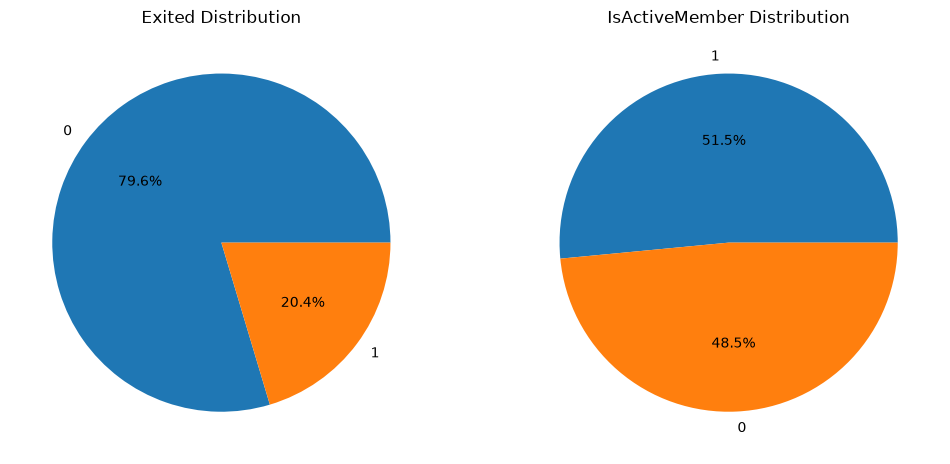

In [142]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,2,figsize=(12,6))
piefeature=['Exited','IsActiveMember']
for i,col in enumerate (piefeature):
    counts=dataset[col].value_counts()
    ax[i].pie(counts.values,labels=counts.index,autopct='%1.1f%%')
    ax[i].set_title(f'{col} Distribution')


In [143]:
X=dataset.iloc[:,3:13]
y=dataset.iloc[:,13]
catefeature=['Gender','Geography']

mappings={}
for col in catefeature:
    cat_series=X[col].astype('category')
    mappings[col]={val: i for i,val in enumerate(cat_series.cat.categories)}
# dictionary of dictionaries
# mappings = {
#     'Gender': {'Female': 0, 'Male': 1},
#     'Geography':{'France': 0, 'Germany': 1, 'Spain': 2},
# }
    X[col]=cat_series.cat.codes
print(mappings)

#     mapping = dict(enumerate(X[col].astype('category').cat.categories))
#     mapping_reversed = {val: i for i, val in enumerate(X[col].astype('category').cat.categories)}
#     print(mapping_reversed)
# for i,col in enumerate(catefeature):
#     X[col]=X[col].astype('category').cat.codes

X.info()

{'Gender': {'Female': 0, 'Male': 1}, 'Geography': {'France': 0, 'Germany': 1, 'Spain': 2}}
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  int8   
 2   Gender           10000 non-null  int8   
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
dtypes: float64(2), int64(6), int8(2)
memory usage: 644.7 KB


In [144]:
print(X['Gender'].value_counts())
print(X['Geography'].value_counts())
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=0)

Gender
1    5457
0    4543
Name: count, dtype: int64
Geography
0    5014
1    2509
2    2477
Name: count, dtype: int64


In [145]:
import xgboost as xgb
# Dmatrix: special data structure for faster training and less memory 
xgb_train=xgb.DMatrix(X_train,y_train)
xgb_test=xgb.DMatrix(X_test,y_test)

In [146]:
params={
    'objective':'binary:logistic',
    # for binaray classification
    'max_depth':3,
    'learning_rate':0.1,
}
model=xgb.train(params=params,dtrain=xgb_train,num_boost_round=50)
preds=model.predict(xgb_test)
# output probability of belonging to the group 
import numpy as np
preds=np.round(preds)
df=pd.DataFrame(preds)
print(df.value_counts())
from sklearn.metrics import classification_report
print(classification_report(y_test,preds))

0  
0.0    2210
1.0     290
Name: count, dtype: int64
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1991
           1       0.79      0.45      0.58       509

    accuracy                           0.86      2500
   macro avg       0.83      0.71      0.75      2500
weighted avg       0.86      0.86      0.85      2500

